# code_200 · Deferral creates a service obligation

**Book:** section 37.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_37_GUIDE.md), [execution evidence](../CHAPTER_37_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_200).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Probability and interval contracts identify fitting and calibration roles, uncertainty sources, assessment units and decision costs. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7900;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7900


<a id="choose-a-deferral-policy"></a>
 ## Treat confidence and support as different admission questions
 Generate 1,000 source, 400 calibration, 400 selection and 1,000 final independent buildings. Source loads lie in [−2,2]. Later cohorts include unsupported loads 2.1–4 at rates 0%, 15% and 35% respectively for calibration, selection and final, with a reversed response law there. A source-fitted histogram classifier is positively temperature-calibrated on the separate familiar calibration cohort. The declared support gate rejects every load outside [−2,2], regardless of confidence. Selection compares a fixed 0.5–0.99 confidence grid, requiring empirical accepted error≤0.12 and review fraction≤0.30, then maximizes automation coverage. These are development constraints, not finite-sample risk guarantees. If no grid candidate is feasible, record that explicitly and defer all; do not invent a successful operating point.

 Report confidence-only and gated final coverage-risk curves descriptively. The actual deployed teaching policy is the already chosen threshold with the support gate, never reselected from final errors. Empty accepted sets have undefined risk, represented as null. A high-confidence extrapolation can be systematically wrong under the changed law.


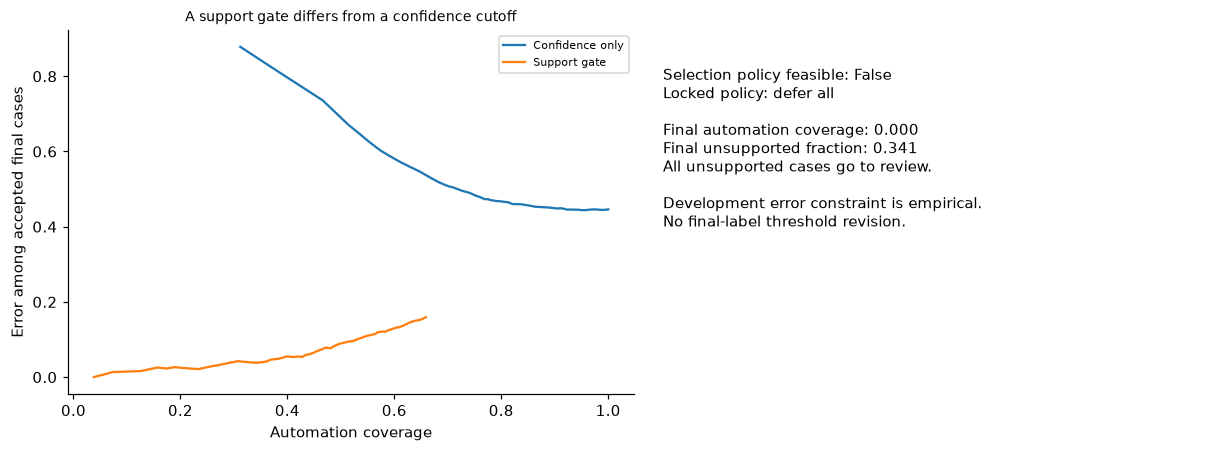

In [2]:
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.optimize import minimize_scalar
def cohort(n,shift_fraction=0):
    x=np.c_[rng.uniform(-2,2,n),rng.normal(size=n)];shift=rng.random(n)<shift_fraction;x[shift,0]=rng.uniform(2.1,4,shift.sum());prob=expit(2*x[:,0]+.4*x[:,1]);prob[shift]=expit(-2.5*x[shift,0]);return x,rng.binomial(1,prob)
xs,ys=cohort(1000);xc,yc=cohort(400);xd,yd=cohort(400,.15);xf,yf=cohort(1000,.35);model=HistGradientBoostingClassifier(max_iter=80,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);lc=model.decision_function(xc);fit=minimize_scalar(lambda z:np.mean(np.logaddexp(0,lc/np.exp(z))-yc*lc/np.exp(z)),bounds=(-3,3),method='bounded');assert fit.success;T=float(np.exp(fit.x));pdv=expit(model.decision_function(xd)/T);pf=expit(model.decision_function(xf)/T);support_d=(abs(xd[:,0])<=2);support_f=(abs(xf[:,0])<=2);confidence_d=np.maximum(pdv,1-pdv);confidence_f=np.maximum(pf,1-pf);grid=np.linspace(.5,.99,50);selection_rows=[]
for t in grid:
    accepted=support_d&(confidence_d>=t);coverage=float(accepted.mean());risk=float(np.mean((pdv[accepted]>=.5)!=yd[accepted])) if accepted.any() else None;selection_rows.append({'threshold':float(t),'coverage':coverage,'risk':risk,'review_fraction':1-coverage})
feasible=[r for r in selection_rows if r['risk'] is not None and r['risk']<=.12 and r['review_fraction']<=.30];chosen=max(feasible,key=lambda r:(r['coverage'],-r['threshold'])) if feasible else None;threshold=chosen['threshold'] if chosen else 1.01;accepted=support_f&(confidence_f>=threshold);error=(pf>=.5)!=yf;curves={}
for name,support in [('Confidence only',np.ones(1000,bool)),('Support gate',support_f)]:
    rows=[]
    for t in grid:
        mask=support&(confidence_f>=t);rows.append({'threshold':float(t),'automation_coverage':float(mask.mean()),'accepted_risk':float(error[mask].mean()) if mask.any() else None})
    curves[name]=rows
assert not np.any(accepted&~support_f);assert threshold in [r['threshold'] for r in selection_rows] or chosen is None;RESULTS.update(building_roles=[1000,400,400,1000],temperature=T,empirical_selection_target_risk=.12,empirical_selection_max_review=.30,selection_policy_feasible=bool(feasible),chosen_selection_policy=chosen,locked_threshold=threshold,final_automation_coverage=float(accepted.mean()),final_accepted_risk=float(error[accepted].mean()) if accepted.any() else None,final_unsupported_fraction=float((~support_f).mean()),final_review_fraction=float((~accepted).mean()),final_curve_descriptive_only=curves,development_constraint_is_not_risk_guarantee=True)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,rows in curves.items():
    rows=[r for r in rows if r['accepted_risk'] is not None];axes[0].plot([r['automation_coverage'] for r in rows],[r['accepted_risk'] for r in rows],label=name)
axes[0].set(xlabel='Automation coverage',ylabel='Error among accepted final cases',title='A support gate differs from a confidence cutoff');axes[0].legend(fontsize=7);axes[1].axis('off');axes[1].text(.03,.9,f'Selection policy feasible: {bool(feasible)}\nLocked policy: {"confidence cutoff" if chosen else "defer all"}\n\nFinal automation coverage: {accepted.mean():.3f}\nFinal unsupported fraction: {(~support_f).mean():.3f}\nAll unsupported cases go to review.\n\nDevelopment error constraint is empirical.\nNo final-label threshold revision.',va='top',fontsize=10);plt.show()


<a id="review-service-and-delayed-outcomes"></a>
 ## Execute the review queue instead of treating deferral as free correctness
 Final cases arrive as 100 days of ten buildings. A FIFO review service completes at most three cases daily, including the arrival day. All deferred cases enter it; no case is silently accepted to hide a backlog. Continue the simulation after day 100 until the queue drains, recording pending cases at the evaluation horizon, completion delay and three extra days before an outcome becomes available. Review has an explicit independent 2% error probability in this simulator; it is not an oracle or a guarantee about engineers. Report accepted risk separately from eventual combined error, whole-day probability of any accepted error, review cost eight units per case and automatic cost 0.05 per case. Pending cases are service obligations, not correct predictions. No delayed final label updates the already frozen model or policy.


temperature                                     1.107812
empirical_selection_target_risk                     0.12
empirical_selection_max_review                       0.3
selection_policy_feasible                          False
chosen_selection_policy                             None
locked_threshold                                    1.01
final_automation_coverage                            0.0
final_accepted_risk                                 None
final_unsupported_fraction                         0.341
final_review_fraction                                1.0
development_constraint_is_not_risk_guarantee        True
final_arrival_days                                   100
arrivals_per_day                                      10
review_capacity_per_day                                3
pending_reviews_at_day100                            700
maximum_daily_backlog                                700
mean_review_completion_delay_days                116.667
maximum_review_completion_delay

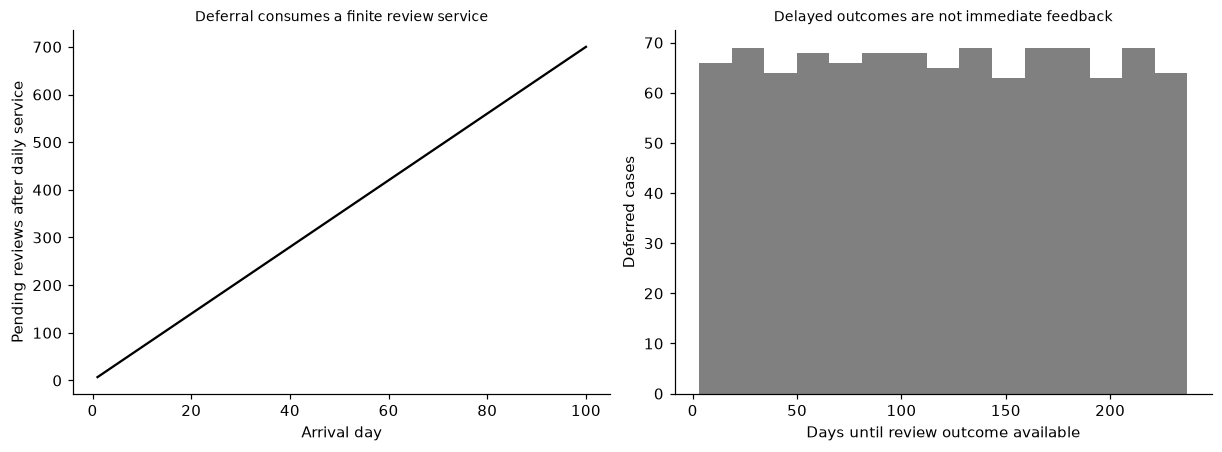

In [3]:
from collections import deque
days=100;arrivals=10;capacity=3;queue=deque();completion=np.full(1000,-1,int);backlog=[];pending_at_horizon=0
for day in range(days):
    queue.extend(i for i in range(day*arrivals,(day+1)*arrivals) if not accepted[i])
    for _ in range(min(capacity,len(queue))):completion[queue.popleft()]=day
    backlog.append(len(queue))
pending_at_horizon=len(queue);day=100
while queue:
    for _ in range(min(capacity,len(queue))):completion[queue.popleft()]=day
    day+=1
reviewed=~accepted;wait=completion[reviewed]-np.flatnonzero(reviewed)//arrivals;review_error=rng.random(reviewed.sum())<.02;combined_errors=int(error[accepted].sum()+review_error.sum());daily_any=(error&accepted).reshape(100,10).any(1);service_cost=float(8*reviewed.sum()+.05*accepted.sum());assert np.all(completion[reviewed]>=np.flatnonzero(reviewed)//arrivals);assert np.all(completion[reviewed]>=0);assert sum(reviewed)==len(wait);RESULTS.update(final_arrival_days=days,arrivals_per_day=arrivals,review_capacity_per_day=capacity,pending_reviews_at_day100=pending_at_horizon,maximum_daily_backlog=int(max(backlog)),mean_review_completion_delay_days=float(wait.mean()) if len(wait) else 0.,maximum_review_completion_delay_days=int(wait.max()) if len(wait) else 0,review_outcome_additional_delay_days=3,eventual_combined_error=combined_errors/1000,review_error_probability_simulator=.02,days_with_any_accepted_error=float(daily_any.mean()),total_service_cost_units=service_cost,service_cost_per_case=service_cost/1000,final_labels_update_policy=False);display(pd.Series({k:v for k,v in RESULTS.items() if not isinstance(v,(dict,list))}));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(np.arange(1,101),backlog,color='black');axes[0].set(xlabel='Arrival day',ylabel='Pending reviews after daily service',title='Deferral consumes a finite review service');axes[1].hist(wait+3,bins=15,color='.5');axes[1].set(xlabel='Days until review outcome available',ylabel='Deferred cases',title='Delayed outcomes are not immediate feedback');plt.show()


In [4]:
summary={'example_id':'code_200','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual independent temperature calibration and empirical deferral selection', 'confidence-only versus explicit unsupported-domain gate', 'accepted-risk automation-coverage and repeated-day error diagnostics', 'executed finite-capacity review queue with delayed outcomes and combined service cost'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual independent temperature calibration and empirical deferral selection", "confidence-only versus explicit unsupported-domain gate", "accepted-risk automation-coverage and repeated-day error diagnostics", "executed finite-capacity review queue with delayed outcomes and combined service cost"], "elapsed_seconds": 0.373, "example_id": "code_200", "hardware": "Darwin arm64 CPU", "results": {"arrivals_per_day": 10, "building_roles": [1000, 400, 400, 1000], "chosen_selection_policy": null, "days_with_any_accepted_error": 0.0, "development_constraint_is_not_risk_guarantee": true, "empirical_selection_max_review": 0.3, "empirical_selection_target_risk": 0.12, "eventual_combined_error": 0.016, "final_accepted_risk": null, "final_arrival_days": 100, "final_automation_coverage": 0.0, "final_curve_descriptive_only": {"Confidence only": [{"accepted_risk": 0.446, "automation_coverage": 1.0, "threshold": 0.5}, {"accepted_risk": 0.444444444444444